In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset

# data set https://huggingface.co/datasets/dair-ai/emotion

In [27]:
emotional_dataset = load_dataset('dair-ai/emotion')
train_text = emotional_dataset['train']['text']
train_label = emotional_dataset['train']['label']
test_text = emotional_dataset['test']['text']
test_label = emotional_dataset['test']['label']


In [28]:
label_names = emotional_dataset['train'].features['label'].names

In [29]:
df_train = pd.DataFrame(
    {
        'text': train_text,
        'label': [label_names[i] for i in train_label]
    }
)

df_test = pd.DataFrame(
    {
        'text': test_text,
        'label': [label_names[i] for i in test_label]
    }
)

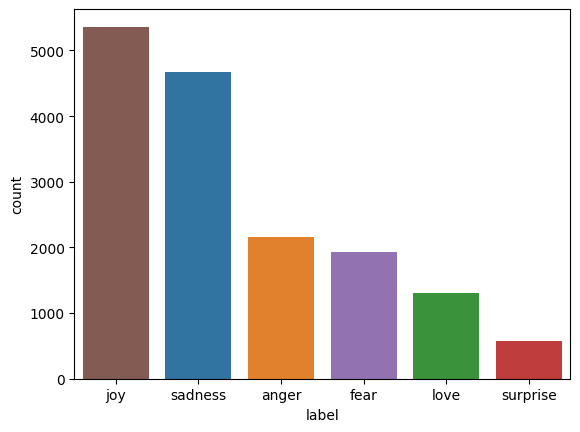

In [30]:
sns.countplot(x='label', data=df_train, order = df_train['label'].value_counts().index, hue='label')
plt.show()

In [31]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000
tokenizer = Tokenizer(num_words=max_words, oov_token='<unknown>')
tokenizer.fit_on_texts(df_train['text'])

train_sequences = tokenizer.texts_to_sequences(df_train['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequence = pad_sequences(train_sequences, maxlen= 50 , padding='post', truncating='post')
padded_test_sequence = pad_sequences(test_sequences, maxlen= 50 , padding='post', truncating='post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_labels))

print("Training sequences:", padded_train_sequence.shape)
print("Training labels:", train_labels.shape)

print("Testing sequences:", padded_test_sequence.shape)
print("Testing labels:", test_labels.shape)

print(f"vocabulary size:{len(tokenizer.word_index)}")
print(f"max word:{(padded_train_sequence.shape[1])}")

Training sequences: (16000, 50)
Training labels: (16000,)
Testing sequences: (2000, 50)
Testing labels: (2000,)
vocabulary size:15213
max word:50


In [32]:
from sklearn.utils import class_weight

train_labels = np.array(train_label)
test_labels = np.array(test_label)

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes = np.unique(train_labels),
    y = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

In [33]:
from tensorflow.keras.callbacks import EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience = 3,
    restore_best_weights = True
)

In [45]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Embedding, Dense, Dropout, LSTM, GRU

rnn_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    SimpleRNN(units=128, return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequence, test_labels)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.2445 - loss: 1.7631
RNN Loss: 1.763062834739685
RNN Accuracy: 0.24449999630451202


In [37]:
rnn_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 45ms/step - accuracy: 0.1633 - loss: 1.8034 - val_accuracy: 0.1685 - val_loss: 1.7845
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.1710 - loss: 1.8040 - val_accuracy: 0.1365 - val_loss: 1.7761
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.1421 - loss: 1.8565 - val_accuracy: 0.1355 - val_loss: 1.8270


In [46]:
lstm_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    LSTM(units=128, return_sequences=True),
    Dropout(0.5),
    LSTM(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

lstm_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequence, test_labels)
print(f"lstm Loss: {lstm_loss}")
print(f"lstm Accuracy: {lstm_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 72s 135ms/step - accuracy: 0.1514 - loss: 1.7956 - val_accuracy: 0.2915 - val_loss: 1.7741
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 86s 143ms/step - accuracy: 0.1702 - loss: 1.7940 - val_accuracy: 0.1120 - val_loss: 1.8002
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 63s 126ms/step - accuracy: 0.1293 - loss: 1.7925 - val_accuracy: 0.3410 - val_loss: 1.7750
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 36ms/step - accuracy: 0.2915 - loss: 1.7741
RNN Loss: 1.774124264717102
RNN Accuracy: 0.2915000021457672


In [48]:
gru_model = Sequential([
    Embedding(input_dim = max_words, output_dim = 128 , input_length = 50),
    GRU(units=128, return_sequences=True),
    Dropout(0.5),
    GRU(units=64),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax') #Output Layer
])

gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

gru_model.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequence, test_labels)
print(f"Gru Loss: {gru_loss}")
print(f"Gru Accuracy: {gru_accuracy}")

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


500/500 ━━━━━━━━━━━━━━━━━━━━ 57s 107ms/step - accuracy: 0.1359 - loss: 1.7968 - val_accuracy: 0.0890 - val_loss: 1.7732
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 71s 141ms/step - accuracy: 0.1636 - loss: 1.7952 - val_accuracy: 0.1375 - val_loss: 1.8009
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 76s 152ms/step - accuracy: 0.1488 - loss: 1.7947 - val_accuracy: 0.0360 - val_loss: 1.7922
63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step - accuracy: 0.0890 - loss: 1.7732
Gru Loss: 1.7732462882995605
Gru Accuracy: 0.08900000154972076


In [52]:
result_df = pd.DataFrame({
        'model':['rnn','lstm','gru'],
        'test_loss':[rnn_loss,lstm_loss,gru_loss],
        'test_accuracy':[rnn_accuracy,lstm_accuracy,gru_accuracy]
    }).sort_values(by='test_accuracy',ascending=False)


result_df

,model,test_loss,test_accuracy
1,lstm,1.774124,0.2915
0,rnn,1.763063,0.2445
2,gru,1.773246,0.0890


In [54]:
from tensorflow.keras.layers import Bidirectional
BiGru = Sequential([
    Embedding(input_dim = max_words, output_dim = 300, input_length = 50),
    Bidirectional(GRU(units=128, return_sequences=True)),
    Dropout(0.5),
    Bidirectional(GRU(units=64)),
    Dropout(0.5),
    Dense(units=num_classes, activation='softmax')
])

BiGru.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

BiGru.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_12 (Embedding)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_2 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_24 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_3 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_25 (Dropout)            │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [55]:
BiGru.fit(
    padded_train_sequence,
    train_labels,
    validation_data=(padded_test_sequence, test_labels),
    epochs = 20,
    batch_size=32,
    class_weight=class_weight_dict,
    callbacks=[early_stopping]
)

BiGru_loss, BiGru_accuracy = BiGru.evaluate(padded_test_sequence, test_labels)
print(f"BiGru Loss: {BiGru_loss}")
print(f"BiGru Accuracy: {BiGru_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 154s 292ms/step - accuracy: 0.5301 - loss: 1.0518 - val_accuracy: 0.8760 - val_loss: 0.4171
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 153s 307ms/step - accuracy: 0.9120 - loss: 0.2477 - val_accuracy: 0.9120 - val_loss: 0.2539
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 189s 282ms/step - accuracy: 0.9416 - loss: 0.1561 - val_accuracy: 0.9115 - val_loss: 0.2907
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 138s 277ms/step - accuracy: 0.9589 - loss: 0.1116 - val_accuracy: 0.9135 - val_loss: 0.2628
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 140s 280ms/step - accuracy: 0.9678 - loss: 0.0906 - val_accuracy: 0.9150 - val_loss: 0.2576
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.9120 - loss: 0.2539
BiGru Loss: 0.25389304757118225
BiGru Accuracy: 0.9120000004768372


63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step


<Axes: >

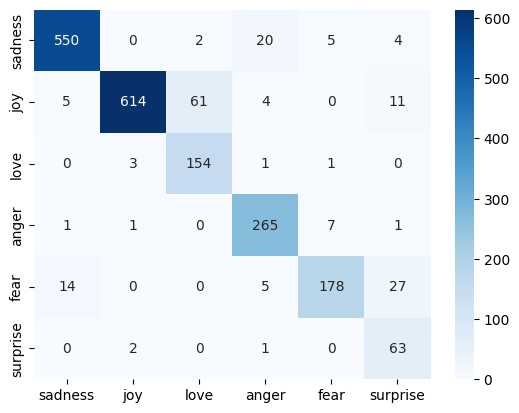

In [56]:
from sklearn.metrics import confusion_matrix

BiGru_predictions = np.argmax(BiGru.predict(padded_test_sequence),axis=1)

sns.heatmap(confusion_matrix(test_label, BiGru_predictions),annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
#

In [64]:
sample_texts = [
    "Hi Saurabh i hate you.!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sequences = tokenizer.texts_to_sequences(sample_texts)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')

sample_predictions = np.argmax(BiGru.predict(sample_padded_sequences), axis=1)

for i in range(len(sample_texts)):
  print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
Text: Hi Saurabh i hate you.!
Predicted Emotion: anger
Text: I feel so alone and hopeless today.
Predicted Emotion: sadness
Text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
Text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
Text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [63]:
import os
import pickle

model_dir = 'Artifacts'
os.makedirs(model_dir, exist_ok=True) #yeh folder hai jiske andar sari exported file aane wali hai

#Save our BiGRU Model
BiGru.save(os.path.join(model_dir, 'BiGRU_Modle.keras'))

#Save the tokenizer model
with open(os.path.join(model_dir, 'tokenizer.pkl'), 'wb') as file:
  pickle.dump(tokenizer, file)